# Mango Leaf Disease Classification (MangoLeafBD) - - Part 3 (DenseNet121 + InceptionV3)

**Dataset:** MangoLeafBD, 4,000 images, 8 classes (7 diseases + healthy), published 2022.
Kaggle: `aryashah2k/mango-leaf-disease-dataset` (add it via *Add Input* → search "Mango Leaf Disease Dataset").

This notebook trains two ImageNet transfer-learning models: **DenseNet121** and **InceptionV3**. It runs the same data pipeline and graphs as the Custom CNN + MobileNetV2 notebook.

**Pipeline:** initial analysis → load dataset → number of classes → duplicate check → image size check →
**graphs before preprocessing** → preprocessing → **graphs after preprocessing** → augmentation → train 2 models → evaluation (**graphs per model**) → model comparison (**line + bar graphs**) → best model (target accuracy > 85%) → final result.

**Notes**
- Turn **Internet ON** in the notebook settings so ImageNet weights can be downloaded (falls back to random init if not).
- Use a **GPU** accelerator (T4 / P100).
- The dataset has ~1,800 distinct leaves; the rest are zoomed/rotated copies. To avoid train/test leakage, near-duplicates are
  grouped and kept inside the same split (see Step 4 and Step 6).

## Step 1. Setup and configuration

In [14]:
import os, glob, hashlib, random, time, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

SEED = 42
random.seed(SEED); np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# ---- configuration ----
DATA_ROOT   = "/kaggle/input/mango-leaf-disease-dataset"   # change if your input folder is named differently
IMG_SIZE    = 224
BATCH_SIZE  = 32
EPOCHS_HEAD = 8      # phase 1: train classifier head (backbone frozen)
EPOCHS_FT   = 8      # phase 2: fine-tune top of backbone
TARGET_ACC  = 0.85   # required accuracy for the best model
NEAR_DUP_THR = 4     # max Hamming distance (of 64-bit dHash) to treat two images as near-duplicates
OUT_DIR     = "/kaggle/working" if os.path.exists("/kaggle/working") else "."

# ---- figure helpers ----
FIG_DIR = os.path.join(OUT_DIR, "figures"); os.makedirs(FIG_DIR, exist_ok=True)
MODEL_COLORS = {"DenseNet121": "#7b5ea7", "InceptionV3": "#e08a1e"}
from matplotlib.ticker import MaxNLocator
def savefig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=150, bbox_inches="tight")

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## Step 2. Load dataset and initial analysis

In [15]:
EXTS = (".jpg", ".jpeg", ".png", ".bmp")
root = DATA_ROOT if os.path.exists(DATA_ROOT) else "/kaggle/input"
rows = []
for dirpath, _, files in os.walk(root):
    for f in files:
        if f.lower().endswith(EXTS):
            rows.append((os.path.join(dirpath, f), os.path.basename(dirpath)))

df = pd.DataFrame(rows, columns=["path", "label"]).sort_values("path").reset_index(drop=True)
print(f"Search root       : {root}")
print(f"Total images      : {len(df)}")
print(f"Folders (classes) : {df['label'].nunique()}")
assert len(df) > 0, "No images found. Check DATA_ROOT / that the dataset is attached to the notebook."
raw_counts = df["label"].value_counts().sort_index()   # kept for the before/after graphs
N_RAW = len(df)
df.head()

Search root       : /kaggle/input
Total images      : 4000
Folders (classes) : 8


,path,label
0,/kaggle/input/datasets/aryashah2k/mango-leaf-d...,Anthracnose
1,/kaggle/input/datasets/aryashah2k/mango-leaf-d...,Anthracnose
2,/kaggle/input/datasets/aryashah2k/mango-leaf-d...,Anthracnose
3,/kaggle/input/datasets/aryashah2k/mango-leaf-d...,Anthracnose
4,/kaggle/input/datasets/aryashah2k/mango-leaf-d...,Anthracnose


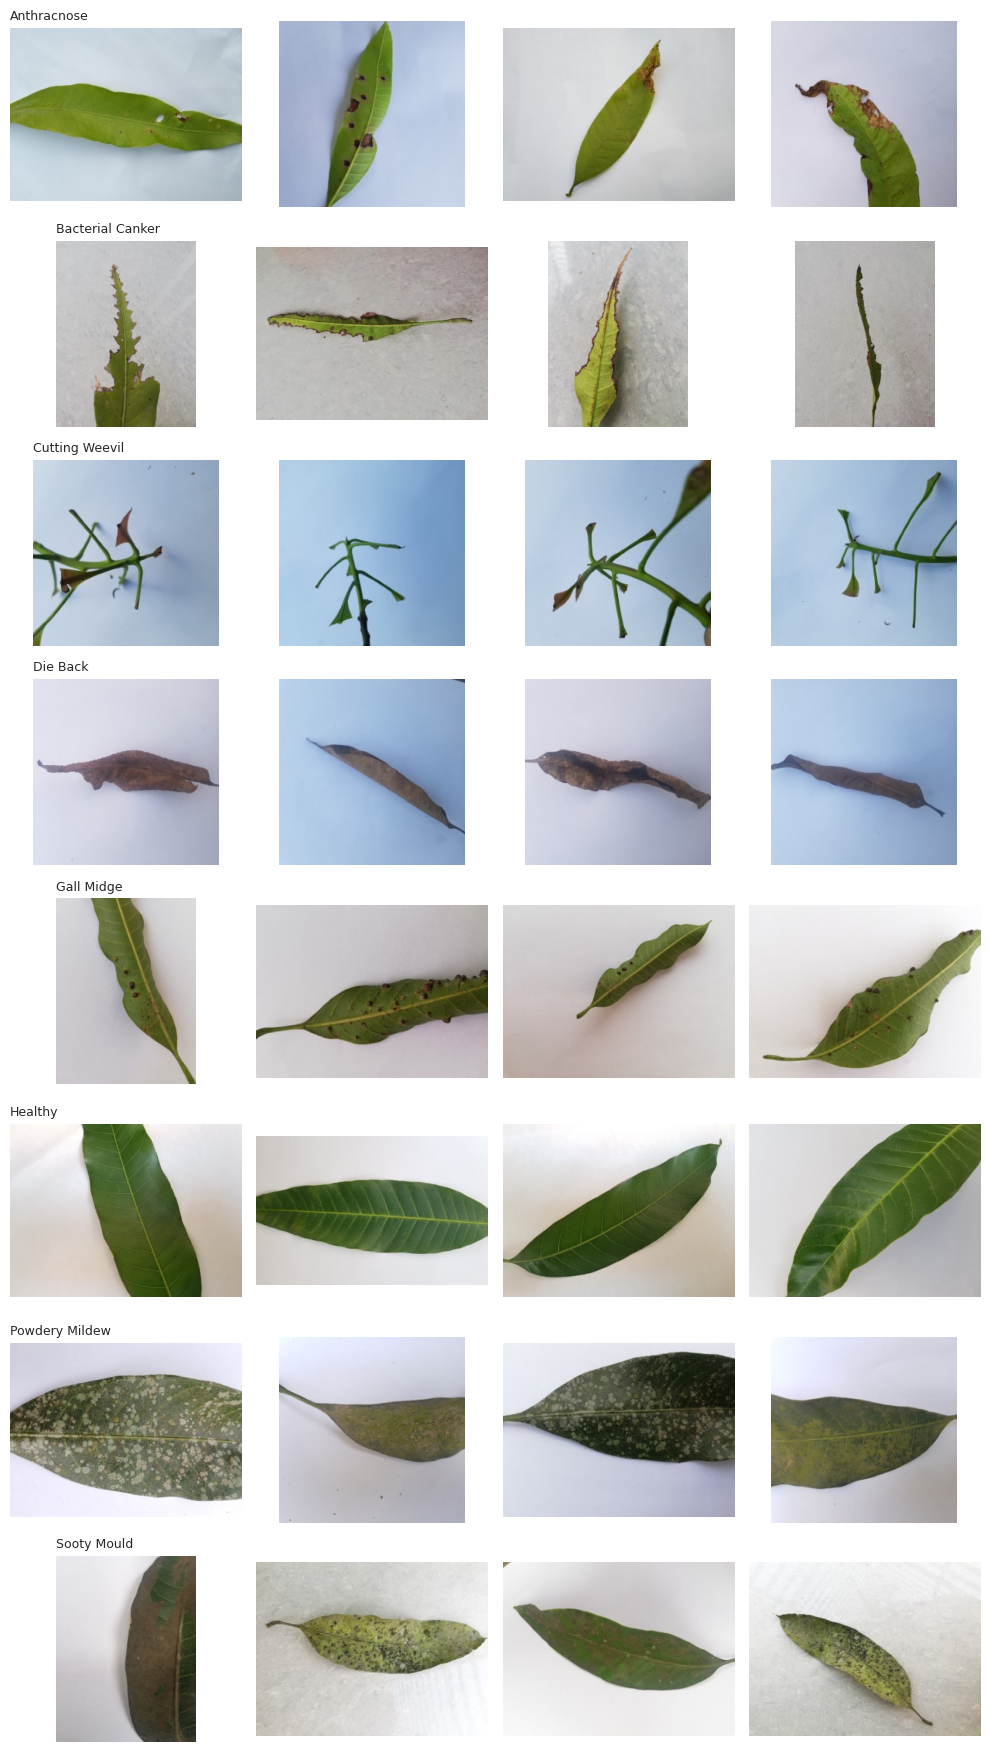

In [16]:
# Sample grid: 4 random images per class
classes = sorted(df["label"].unique())
fig, axes = plt.subplots(len(classes), 4, figsize=(10, 2.2 * len(classes)))
for i, c in enumerate(classes):
    sample = df[df.label == c].sample(4, random_state=SEED)
    for j, p in enumerate(sample.path):
        axes[i, j].imshow(Image.open(p).convert("RGB"))
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(c, fontsize=9, loc="left")
plt.tight_layout(); plt.show()

## Step 3. Number of classes and class balance

Number of classes: 8
label
Anthracnose         500
Bacterial Canker    500
Cutting Weevil      500
Die Back            500
Gall Midge          500
Healthy             500
Powdery Mildew      500
Sooty Mould         500


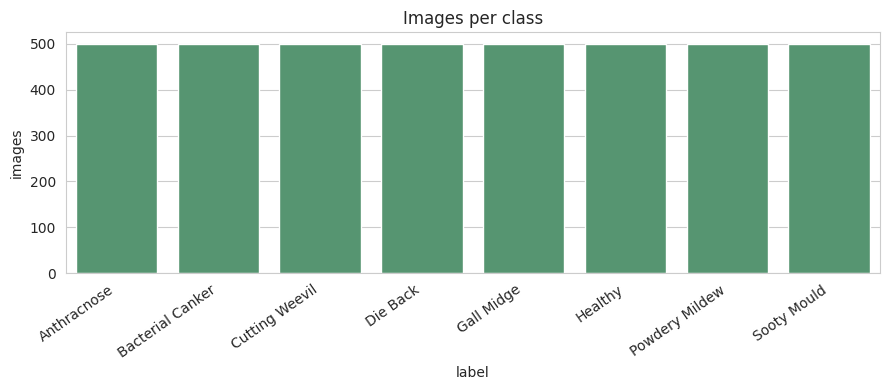

Imbalance ratio (max/min): 1.00  -> balanced


In [17]:
class_counts = df["label"].value_counts().sort_index()
print(f"Number of classes: {len(class_counts)}")
print(class_counts.to_string())

plt.figure(figsize=(9, 4))
sns.barplot(x=class_counts.index, y=class_counts.values, color="#4c9f70")
plt.xticks(rotation=35, ha="right"); plt.ylabel("images"); plt.title("Images per class")
plt.tight_layout(); plt.show()

imbalance = class_counts.max() / class_counts.min()
print(f"Imbalance ratio (max/min): {imbalance:.2f}  ->", "balanced" if imbalance < 1.5 else "imbalanced (consider class weights)")

## Step 4. Duplicate check
Two levels:
1. **Exact duplicates**: identical file bytes (MD5). These are removed.
2. **Near-duplicates**: visually almost identical (64-bit difference hash, Hamming distance ≤ `NEAR_DUP_THR`).
   These are *kept* but assigned a shared `group` id so the train/val/test split never separates them.

In [18]:
def md5_file(p, chunk=1 << 20):
    h = hashlib.md5()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

def dhash(p, size=8):
    img = Image.open(p).convert("L").resize((size + 1, size), Image.LANCZOS)
    a = np.asarray(img, dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).flatten().astype(np.uint8)

md5s, hashes, bad = [], [], []
for i, p in enumerate(df.path):
    try:
        md5s.append(md5_file(p)); hashes.append(dhash(p))
    except Exception as e:
        md5s.append(None); hashes.append(np.zeros(64, dtype=np.uint8)); bad.append(p)

df["md5"] = md5s
print(f"Unreadable / corrupt images: {len(bad)}")
df = df[df.md5.notna()].reset_index(drop=True)
H = np.stack([h for h, m in zip(hashes, md5s) if m is not None])

# --- exact duplicates ---
dup_mask = df.duplicated("md5", keep="first")
print(f"Exact duplicates (same bytes): {dup_mask.sum()}")
keep = ~dup_mask.values
df, H = df[keep].reset_index(drop=True), H[keep]
print(f"Images after removing exact duplicates: {len(df)}")
N_AFTER_DEDUP = len(df)

Unreadable / corrupt images: 0
Exact duplicates (same bytes): 21
Images after removing exact duplicates: 3979


In [19]:
# --- near duplicates via dHash + union-find ---
N = len(df)
Hf = H.astype(np.float32)
dist = Hf @ (1 - Hf).T + (1 - Hf) @ Hf.T          # Hamming distance matrix (N x N)
ii, jj = np.where(np.triu(dist <= NEAR_DUP_THR, k=1))

parent = list(range(N))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
for a, b in zip(ii, jj):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra

df["group"] = [find(i) for i in range(N)]
grp_sizes = df.groupby("group").size()
print(f"Near-duplicate pairs found      : {len(ii)}")
print(f"Groups with more than 1 image   : {(grp_sizes > 1).sum()}")
print(f"Images inside such groups       : {grp_sizes[grp_sizes > 1].sum()}")

# groups whose members carry different labels would be a label-noise red flag
conflict = df.groupby("group")["label"].nunique()
print(f"Groups with conflicting labels  : {(conflict > 1).sum()}")
del dist

Near-duplicate pairs found      : 839
Groups with more than 1 image   : 332
Images inside such groups       : 930
Groups with conflicting labels  : 24


## Step 5. Image size check

         width   height   aspect
count  3979.00  3979.00  3979.00
mean    274.99   260.36     1.09
std      39.75    36.03     0.26
min     187.00    70.00     0.58
25%     240.00   240.00     0.75
50%     240.00   240.00     1.00
75%     320.00   320.00     1.33
max     320.00   320.00     4.57

Most common sizes (W x H):
width  height
320    240       1662
240    240       1173
       320       1017
320    220          5
       226          4
       228          4
       195          3
       229          3
       212          3
240    262          3


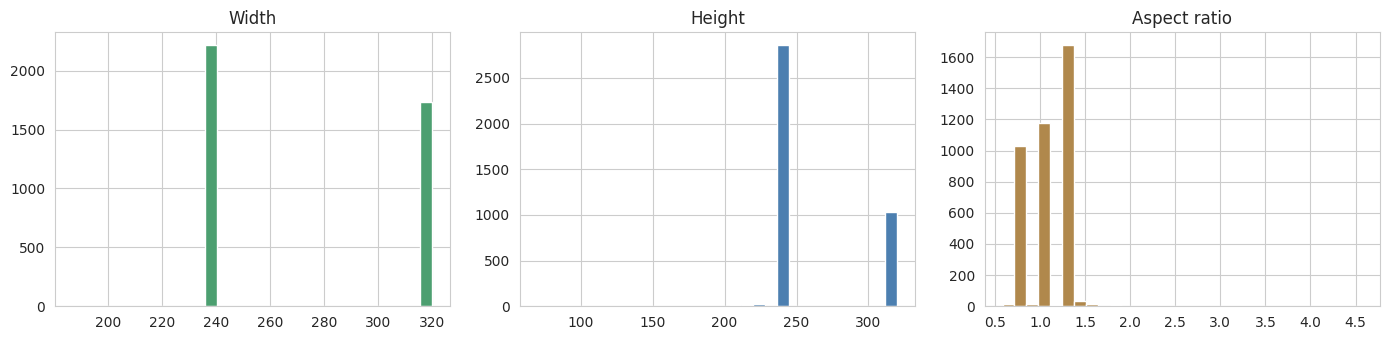

All images share one size: False -> all images will be resized to (224, 224)


In [20]:
sizes = [Image.open(p).size for p in df.path]
df["width"]  = [s[0] for s in sizes]
df["height"] = [s[1] for s in sizes]
df["aspect"] = df.width / df.height

print(df[["width", "height", "aspect"]].describe().round(2).to_string())
print("\nMost common sizes (W x H):")
print(df.groupby(["width", "height"]).size().sort_values(ascending=False).head(10).to_string())

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].hist(df.width, bins=30, color="#4c9f70");  ax[0].set_title("Width")
ax[1].hist(df.height, bins=30, color="#4c7fb0"); ax[1].set_title("Height")
ax[2].hist(df.aspect, bins=30, color="#b0884c"); ax[2].set_title("Aspect ratio")
plt.tight_layout(); plt.show()

uniform = df[["width", "height"]].drop_duplicates().shape[0] == 1
print("All images share one size:", uniform, "-> all images will be resized to", (IMG_SIZE, IMG_SIZE))

### Graphs BEFORE preprocessing (raw images)
- **Bar:** images per class (raw, including duplicates).
- **Line:** image width/height spread (sorted) - the images are not one size.
- **Line:** pixel-intensity distribution per RGB channel (0-255) on a 300-image sample.

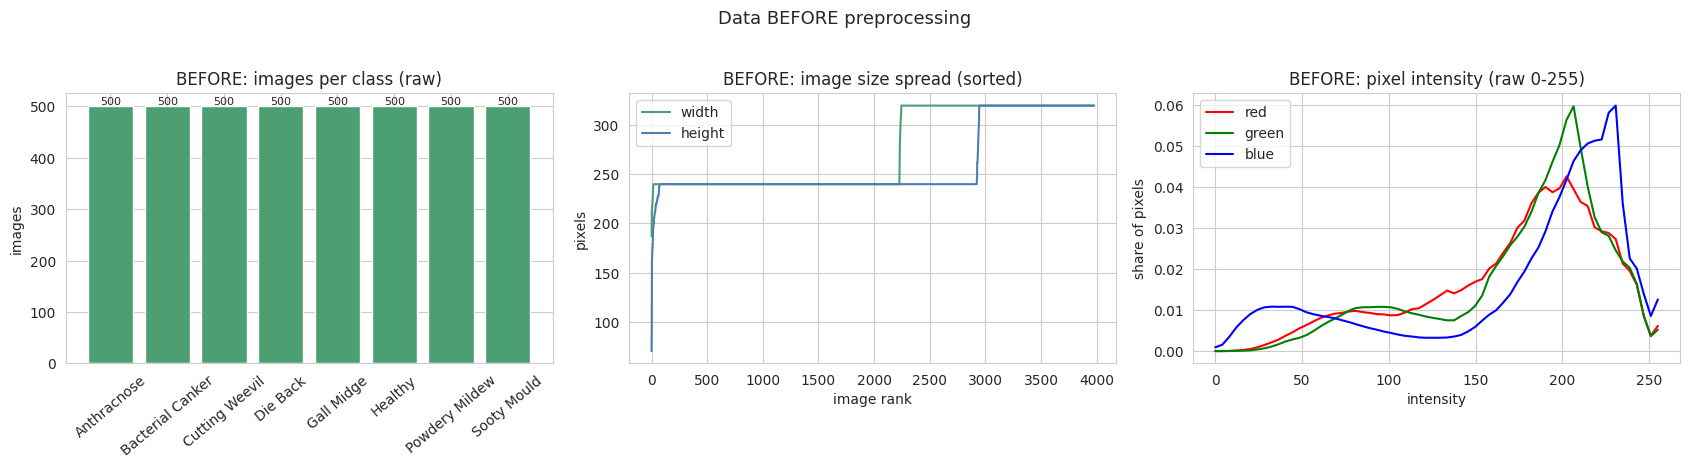

In [21]:
sample_raw = df.sample(min(300, len(df)), random_state=SEED)

def channel_hist(img_iter, vmax, bins=64):
    h = np.zeros((3, bins))
    for a in img_iter:
        for c in range(3):
            h[c] += np.histogram(a[..., c], bins=bins, range=(0, vmax))[0]
    return h / h.sum(axis=1, keepdims=True)

raw_hist = channel_hist((np.asarray(Image.open(p).convert("RGB"), dtype=np.float32) for p in sample_raw.path), 255)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

# bar: images per class (raw)
bars = ax[0].bar(raw_counts.index, raw_counts.values, color="#4c9f70")
ax[0].bar_label(bars, fontsize=8)
ax[0].set_title("BEFORE: images per class (raw)"); ax[0].set_ylabel("images")
ax[0].tick_params(axis="x", rotation=40)

# line: width / height spread
ax[1].plot(np.sort(df.width.values),  color="#4c9f70", label="width")
ax[1].plot(np.sort(df.height.values), color="#4c7fb0", label="height")
ax[1].set_title("BEFORE: image size spread (sorted)"); ax[1].set_xlabel("image rank"); ax[1].set_ylabel("pixels"); ax[1].legend()

# line: pixel intensity per channel
xs = np.linspace(0, 255, raw_hist.shape[1])
for c, col in enumerate(("red", "green", "blue")):
    ax[2].plot(xs, raw_hist[c], color=col, label=col)
ax[2].set_title("BEFORE: pixel intensity (raw 0-255)"); ax[2].set_xlabel("intensity"); ax[2].set_ylabel("share of pixels"); ax[2].legend()

fig.suptitle("Data BEFORE preprocessing", fontsize=13, y=1.03)
savefig("01_before_preprocessing"); plt.show()

## Step 6. Preprocessing
- Label-encode the folder names.
- **Group-aware** 70 / 15 / 15 train / val / test split (near-duplicates stay together).
- `tf.data` pipeline: decode → resize to 224×224 → batch → prefetch.
- Backbone-specific pixel scaling (`preprocess_input`) is applied *inside* each model.

In [22]:
class_names = sorted(df.label.unique())
label2id = {c: i for i, c in enumerate(class_names)}
df["y"] = df.label.map(label2id)
NUM_CLASSES = len(class_names)

gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
tr_idx, tmp_idx = next(gss1.split(df, df.y, groups=df.group))
tmp = df.iloc[tmp_idx]
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
va_rel, te_rel = next(gss2.split(tmp, tmp.y, groups=tmp.group))

train_df, val_df, test_df = df.iloc[tr_idx], tmp.iloc[va_rel], tmp.iloc[te_rel]
print(f"train={len(train_df)}  val={len(val_df)}  test={len(test_df)}")
print(pd.DataFrame({"train": train_df.label.value_counts(),
                    "val": val_df.label.value_counts(),
                    "test": test_df.label.value_counts()}).fillna(0).astype(int).to_string())

def _load(path, y):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return img, y

def make_ds(frame, training):
    ds = tf.data.Dataset.from_tensor_slices((frame.path.values, frame.y.values.astype("int32")))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(_load, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train_df, True), make_ds(val_df, False), make_ds(test_df, False)

train=2839  val=566  test=574
                  train  val  test
label                             
Anthracnose         323   80    83
Bacterial Canker    354   75    71
Cutting Weevil      336   68    96
Die Back            394   47    52
Gall Midge          366   56    78
Healthy             356   78    66
Powdery Mildew      364   79    57
Sooty Mould         346   83    71


### Graphs AFTER preprocessing
Same 300 sample images, now pushed through the real `_load` pipeline (resize to 224x224) and scaled to [0, 1].
- **Bar:** train / val / test images per class after the group-aware split.
- **Line:** image size after resizing vs. before (flat line = every image is now 224x224).
- **Line:** pixel-intensity distribution per channel after scaling.

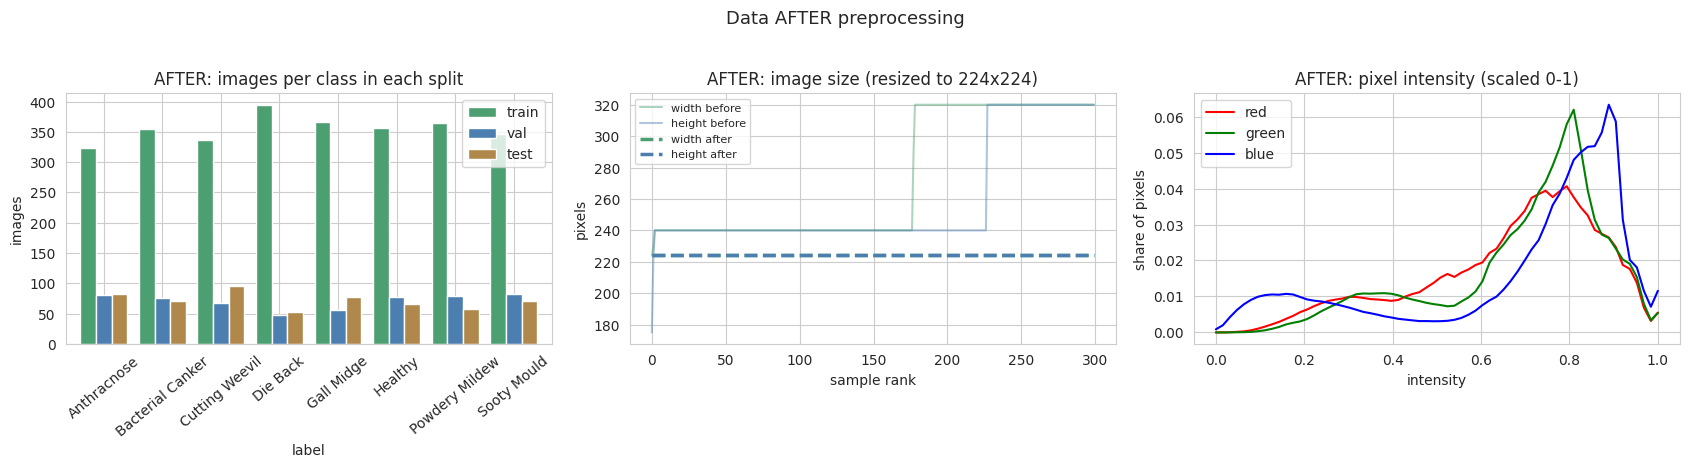

In [23]:
proc_imgs = []
for p in sample_raw.path:
    img, _ = _load(tf.constant(p), 0)
    proc_imgs.append(img.numpy() / 255.0)           # scaled to [0,1] for the graphs; each backbone applies its own preprocess_input inside the model
proc_hist = channel_hist(proc_imgs, 1.0)
proc_shapes = np.array([a.shape[:2] for a in proc_imgs])

split_counts = pd.DataFrame({"train": train_df.label.value_counts(),
                             "val":   val_df.label.value_counts(),
                             "test":  test_df.label.value_counts()}).fillna(0).astype(int).sort_index()

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

# bar: split per class
split_counts.plot(kind="bar", ax=ax[0], width=0.8, color=["#4c9f70", "#4c7fb0", "#b0884c"])
ax[0].set_title("AFTER: images per class in each split"); ax[0].set_ylabel("images")
ax[0].tick_params(axis="x", rotation=40)

# line: sizes before vs after
ax[1].plot(np.sort(sample_raw.width.values),  color="#4c9f70", alpha=0.45, label="width before")
ax[1].plot(np.sort(sample_raw.height.values), color="#4c7fb0", alpha=0.45, label="height before")
ax[1].plot(np.sort(proc_shapes[:, 1]), color="#4c9f70", lw=2.5, ls="--", label="width after")
ax[1].plot(np.sort(proc_shapes[:, 0]), color="#4c7fb0", lw=2.5, ls="--", label="height after")
ax[1].set_title("AFTER: image size (resized to 224x224)"); ax[1].set_xlabel("sample rank"); ax[1].set_ylabel("pixels"); ax[1].legend(fontsize=8)

# line: intensity after scaling
xs1 = np.linspace(0, 1, proc_hist.shape[1])
for c, col in enumerate(("red", "green", "blue")):
    ax[2].plot(xs1, proc_hist[c], color=col, label=col)
ax[2].set_title("AFTER: pixel intensity (scaled 0-1)"); ax[2].set_xlabel("intensity"); ax[2].set_ylabel("share of pixels"); ax[2].legend()

fig.suptitle("Data AFTER preprocessing", fontsize=13, y=1.03)
savefig("02_after_preprocessing"); plt.show()

### Before vs after preprocessing (side by side)

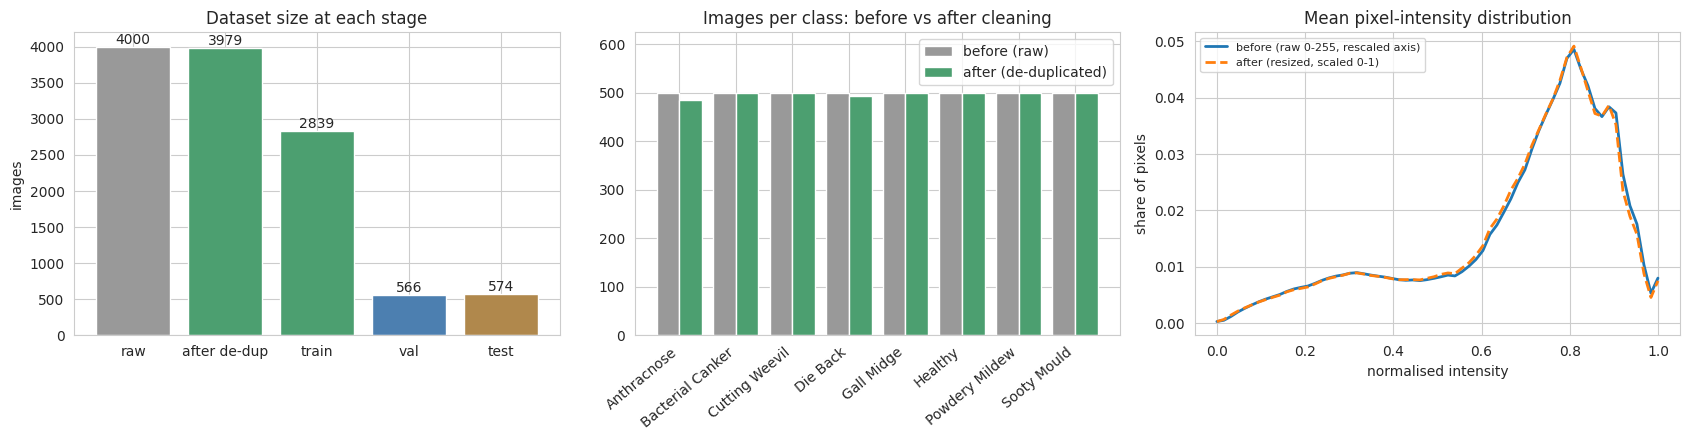

In [24]:
clean_counts = df["label"].value_counts().sort_index()
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

# bar: dataset size at each stage
stages = ["raw", "after de-dup", "train", "val", "test"]
vals = [N_RAW, N_AFTER_DEDUP, len(train_df), len(val_df), len(test_df)]
bars = ax[0].bar(stages, vals, color=["#999999", "#4c9f70", "#4c9f70", "#4c7fb0", "#b0884c"])
ax[0].bar_label(bars); ax[0].set_title("Dataset size at each stage"); ax[0].set_ylabel("images")

# bar: per-class raw vs cleaned
x = np.arange(len(clean_counts)); w = 0.4
ax[1].bar(x - w/2, raw_counts.reindex(clean_counts.index).values, w, label="before (raw)", color="#999999")
ax[1].bar(x + w/2, clean_counts.values, w, label="after (de-duplicated)", color="#4c9f70")
ax[1].set_xticks(x); ax[1].set_xticklabels(clean_counts.index, rotation=40, ha="right")
ax[1].set_ylim(0, raw_counts.max() * 1.25)
ax[1].set_title("Images per class: before vs after cleaning"); ax[1].legend()

# line: mean intensity histogram, both on a 0-1 axis
ax[2].plot(np.linspace(0, 1, raw_hist.shape[1]),  raw_hist.mean(0),  lw=2, label="before (raw 0-255, rescaled axis)")
ax[2].plot(np.linspace(0, 1, proc_hist.shape[1]), proc_hist.mean(0), lw=2, ls="--", label="after (resized, scaled 0-1)")
ax[2].set_title("Mean pixel-intensity distribution"); ax[2].set_xlabel("normalised intensity"); ax[2].set_ylabel("share of pixels"); ax[2].legend(fontsize=8)

savefig("03_before_vs_after_summary"); plt.show()

## Step 7. Data augmentation
Applied to the **training** data only (the layers are inactive at validation/test time).

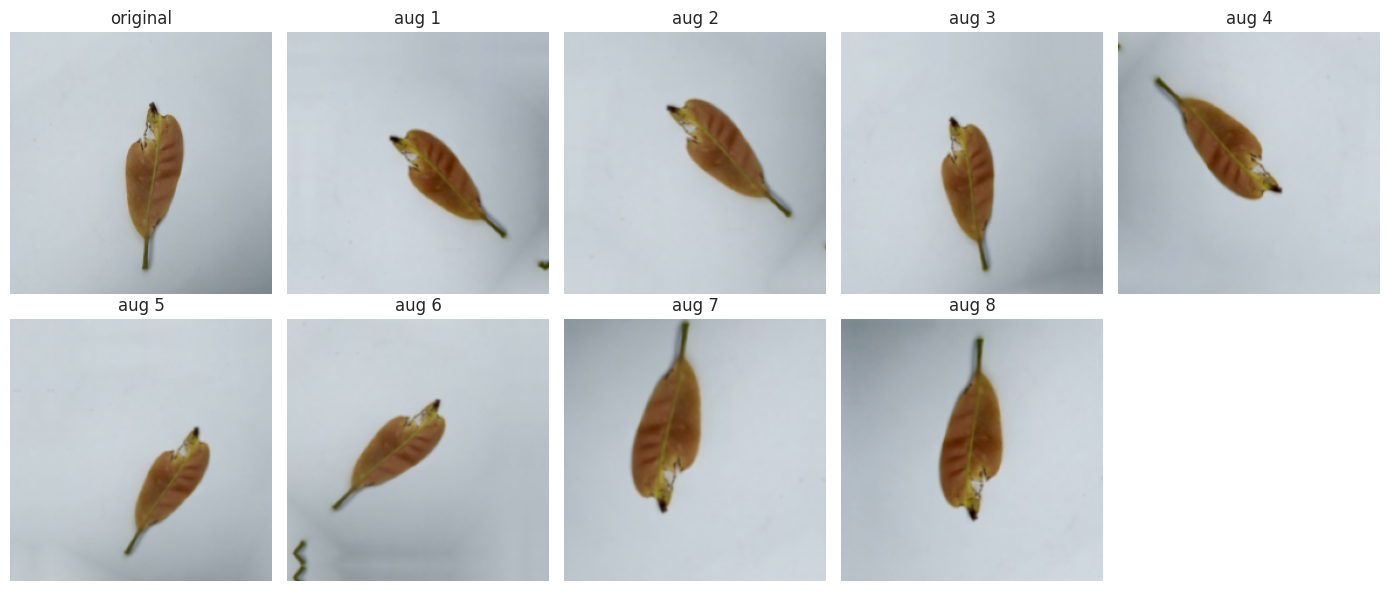

In [25]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.15),
], name="augmentation")

# preview: one image, 8 augmented versions
x_batch, _ = next(iter(train_ds))
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
axes[0, 0].imshow(x_batch[0].numpy().astype("uint8")); axes[0, 0].set_title("original")
for k, ax in enumerate(axes.flat[1:9], 1):
    ax.imshow(augment(x_batch[:1], training=True)[0].numpy().astype("uint8")); ax.set_title(f"aug {k}")
for ax in axes.flat: ax.axis("off")
plt.tight_layout(); plt.show()

## Step 8. Model training (2 models)
| # | Model | Type |
|---|---|---|
| 1 | DenseNet121 | ImageNet transfer learning |
| 2 | InceptionV3 | ImageNet transfer learning |

Phase 1 trains the head with a frozen backbone, phase 2 fine-tunes the top 30 backbone layers at a low learning rate.


In [26]:
from tensorflow.keras.applications import DenseNet121, InceptionV3
from tensorflow.keras.applications import densenet, inception_v3

INPUT_SHAPE = (IMG_SIZE, IMG_SIZE, 3)

def build_transfer(name):
    cfg = {
        "DenseNet121":  (DenseNet121,  densenet.preprocess_input),
        "InceptionV3":  (InceptionV3,  inception_v3.preprocess_input),
    }[name]
    try:
        base = cfg[0](include_top=False, weights="imagenet", input_shape=INPUT_SHAPE)
        pretrained = True
    except Exception as e:
        print(f"[{name}] could not load ImageNet weights ({type(e).__name__}); using random init. Enable Internet for best results.")
        base = cfg[0](include_top=False, weights=None, input_shape=INPUT_SHAPE)
        pretrained = False
    base.trainable = not pretrained
    inp = keras.Input(INPUT_SHAPE)
    x = augment(inp)
    x = layers.Lambda(cfg[1], name="preprocess")(x)
    x = base(x, training=False if pretrained else None)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inp, out, name=name), base

def callbacks():
    return [keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=4, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7, verbose=0)]

def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])

def merge_hist(*hs):
    out = {}
    for h in hs:
        for k, v in h.history.items():
            out.setdefault(k, []).extend(v)
    return out

def train_model(name):
    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    t0 = time.time()
    model, base = build_transfer(name)
    compile_model(model, 1e-3)
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD, callbacks=callbacks(), verbose=2)
    base.trainable = True
    for layer in base.layers[:-30]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    compile_model(model, 1e-5)
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FT, callbacks=callbacks(), verbose=2)
    hist = merge_hist(h1, h2)
    hist["ft_start"] = len(h1.history["loss"])   # epoch where fine-tuning begins (used in the graphs)
    return model, hist, time.time() - t0

MODEL_NAMES = ['DenseNet121', 'InceptionV3']
trained, histories, train_time = {}, {}, {}
for name in MODEL_NAMES:
    print("=" * 70, f"\nTraining {name}\n", "=" * 70, sep="")
    trained[name], histories[name], train_time[name] = train_model(name)
    print(f"{name} finished in {train_time[name] / 60:.1f} min")


Training DenseNet121
Epoch 1/8
89/89 - 34s - 387ms/step - accuracy: 0.6520 - loss: 1.0816 - val_accuracy: 0.9081 - val_loss: 0.3607 - learning_rate: 0.0010
Epoch 2/8
89/89 - 16s - 178ms/step - accuracy: 0.9081 - loss: 0.3706 - val_accuracy: 0.9629 - val_loss: 0.1842 - learning_rate: 0.0010
Epoch 3/8
89/89 - 16s - 182ms/step - accuracy: 0.9433 - loss: 0.2442 - val_accuracy: 0.9806 - val_loss: 0.1299 - learning_rate: 0.0010
Epoch 4/8
89/89 - 16s - 182ms/step - accuracy: 0.9560 - loss: 0.1832 - val_accuracy: 0.9841 - val_loss: 0.1004 - learning_rate: 0.0010
Epoch 5/8
89/89 - 16s - 178ms/step - accuracy: 0.9648 - loss: 0.1436 - val_accuracy: 0.9912 - val_loss: 0.0812 - learning_rate: 0.0010
Epoch 6/8
89/89 - 15s - 173ms/step - accuracy: 0.9697 - loss: 0.1330 - val_accuracy: 0.9894 - val_loss: 0.0629 - learning_rate: 0.0010
Epoch 7/8
89/89 - 16s - 177ms/step - accuracy: 0.9715 - loss: 0.1187 - val_accuracy: 0.9929 - val_loss: 0.0571 - learning_rate: 0.0010
Epoch 8/8
89/89 - 16s - 180ms/step

## Step 9. Evaluation (held-out test set)
For **each model**: line graphs (train vs val accuracy and loss), bar graph (per-class precision / recall / F1) and a confusion matrix.

In [27]:
y_true = test_df.y.values
results, preds, reports = [], {}, {}
for name, model in trained.items():
    prob = model.predict(test_ds, verbose=0)
    y_pred = prob.argmax(1)
    preds[name] = y_pred
    h = histories[name]
    reports[name] = classification_report(y_true, y_pred, target_names=class_names, digits=3,
                                          output_dict=True, zero_division=0)
    results.append({
        "Model": name,
        "Val Acc": max(h["val_accuracy"]),
        "Test Acc": accuracy_score(y_true, y_pred),
        "Test Macro-F1": f1_score(y_true, y_pred, average="macro"),
        "Params (M)": model.count_params() / 1e6,
        "Train time (min)": train_time[name] / 60,
    })
    print(f"\n=== {name} ===")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3, zero_division=0))



=== DenseNet121 ===
                  precision    recall  f1-score   support

     Anthracnose      1.000     1.000     1.000        83
Bacterial Canker      1.000     1.000     1.000        71
  Cutting Weevil      1.000     1.000     1.000        96
        Die Back      1.000     1.000     1.000        52
      Gall Midge      0.987     1.000     0.994        78
         Healthy      1.000     1.000     1.000        66
  Powdery Mildew      1.000     1.000     1.000        57
     Sooty Mould      1.000     0.986     0.993        71

        accuracy                          0.998       574
       macro avg      0.998     0.998     0.998       574
    weighted avg      0.998     0.998     0.998       574


=== InceptionV3 ===
                  precision    recall  f1-score   support

     Anthracnose      1.000     0.940     0.969        83
Bacterial Canker      1.000     0.972     0.986        71
  Cutting Weevil      1.000     1.000     1.000        96
        Die Back      1.00

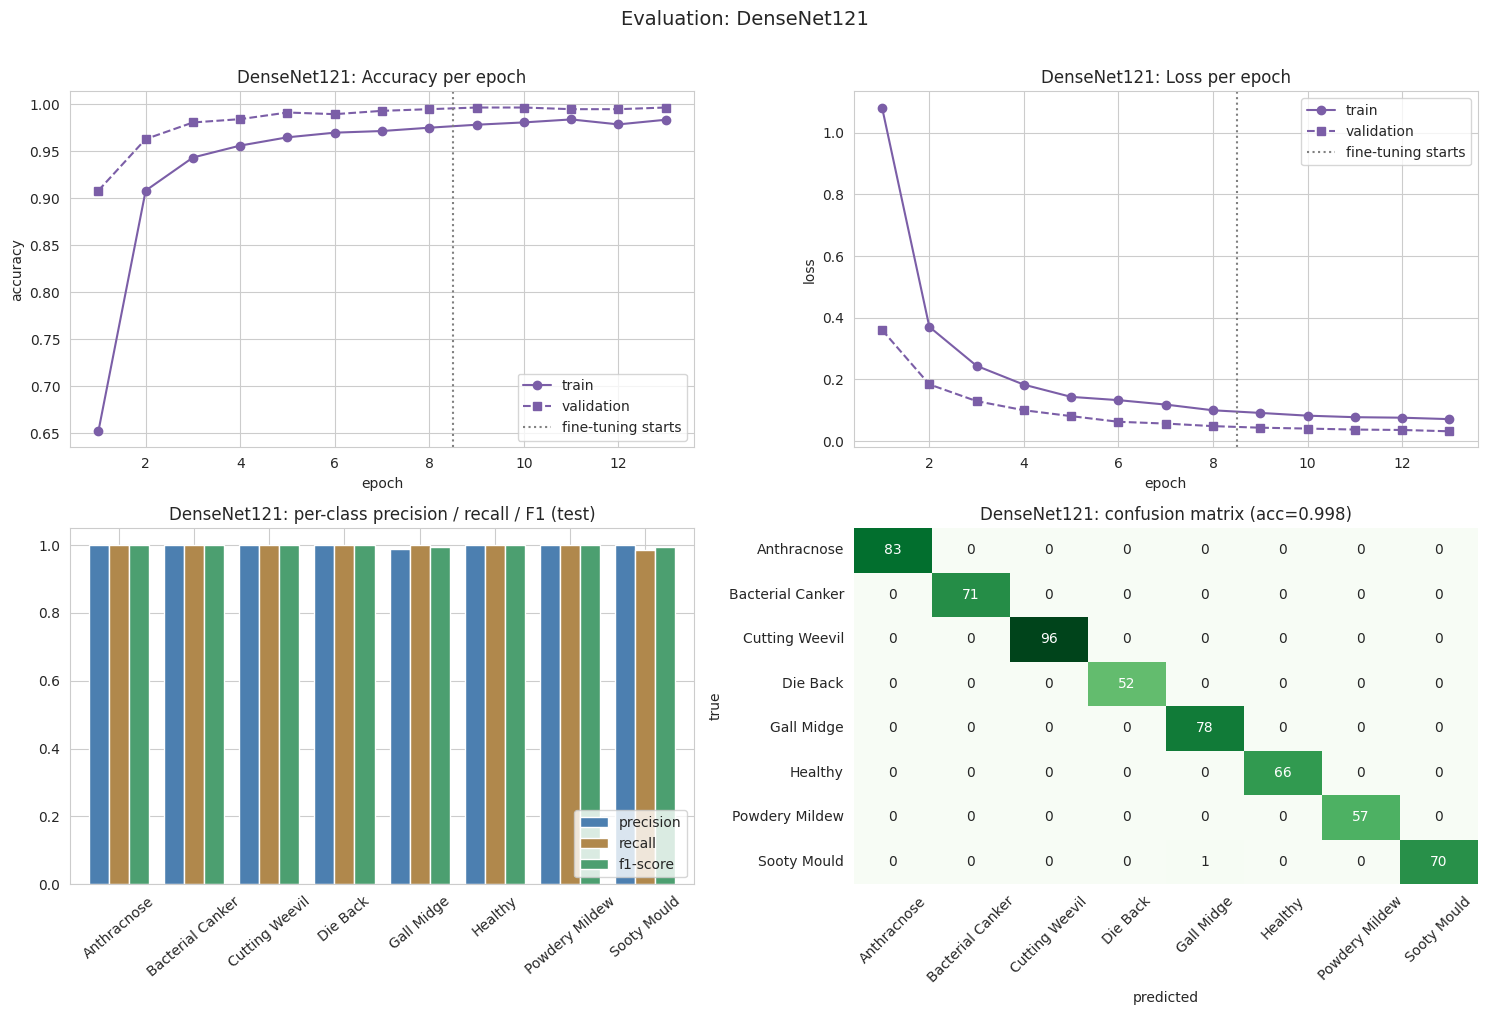

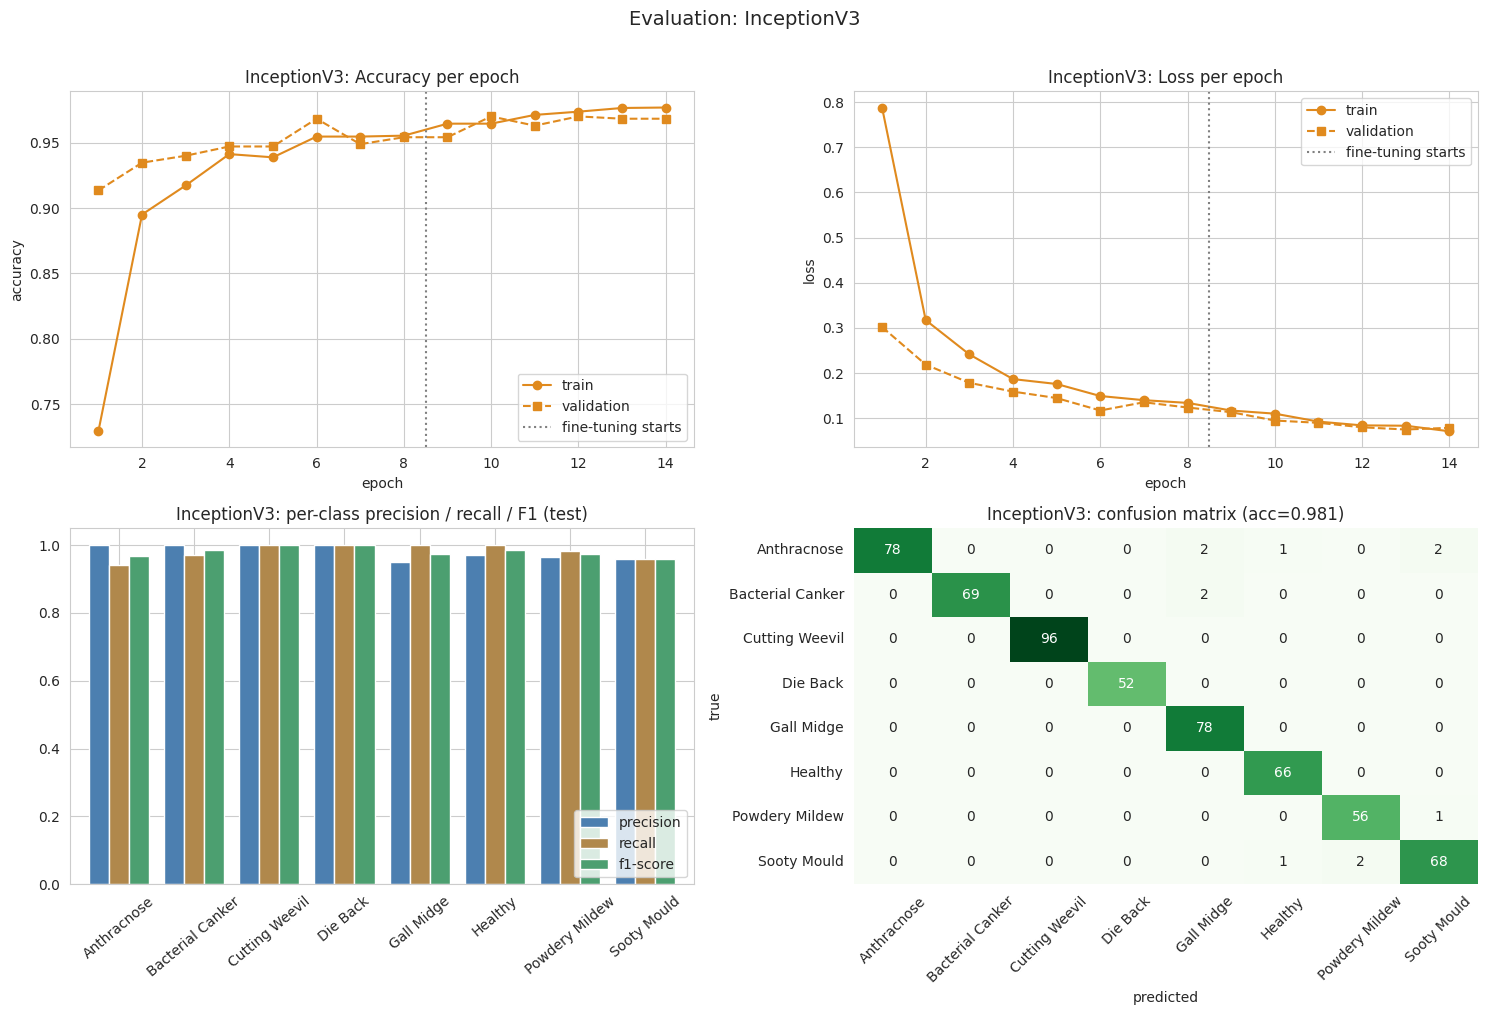

In [28]:
def plot_model_eval(name):
    h = histories[name]
    ep = np.arange(1, len(h["accuracy"]) + 1)
    col = MODEL_COLORS[name]
    fig, ax = plt.subplots(2, 2, figsize=(15, 10))

    # line: accuracy and loss, train vs val
    for a, (k, title) in zip(ax[0], (("accuracy", "Accuracy"), ("loss", "Loss"))):
        a.plot(ep, h[k], marker="o", color=col, label="train")
        a.plot(ep, h["val_" + k], marker="s", color=col, ls="--", label="validation")
        if h.get("ft_start"):
            a.axvline(h["ft_start"] + 0.5, color="grey", ls=":", label="fine-tuning starts")
        a.xaxis.set_major_locator(MaxNLocator(integer=True)); a.set_title(f"{name}: {title} per epoch"); a.set_xlabel("epoch"); a.set_ylabel(k); a.legend()

    # bar: per-class precision / recall / F1
    rep = reports[name]
    prf = pd.DataFrame({m: [rep[c][m] for c in class_names] for m in ("precision", "recall", "f1-score")},
                       index=class_names)
    prf.plot(kind="bar", ax=ax[1, 0], width=0.8, color=["#4c7fb0", "#b0884c", "#4c9f70"])
    ax[1, 0].set_ylim(0, 1.05); ax[1, 0].set_title(f"{name}: per-class precision / recall / F1 (test)")
    ax[1, 0].tick_params(axis="x", rotation=40); ax[1, 0].legend(loc="lower right")

    # confusion matrix
    cm = confusion_matrix(y_true, preds[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False, ax=ax[1, 1],
                xticklabels=class_names, yticklabels=class_names)
    ax[1, 1].set_title(f"{name}: confusion matrix (acc={accuracy_score(y_true, preds[name]):.3f})")
    ax[1, 1].set_xlabel("predicted"); ax[1, 1].set_ylabel("true"); ax[1, 1].tick_params(axis="x", rotation=45)

    fig.suptitle(f"Evaluation: {name}", fontsize=14, y=1.01)
    savefig(f"04_eval_{name}"); plt.show()

for name in MODEL_NAMES:
    plot_model_eval(name)


## Step 10. Model comparison
Table, then **line graphs** (training curves overlaid) and **bar graphs** (accuracy / F1, per-class F1, size, training time).

In [29]:
res = pd.DataFrame(results).sort_values("Val Acc", ascending=False).reset_index(drop=True)
res.index += 1
display(res.style.format({"Val Acc": "{:.4f}", "Test Acc": "{:.4f}", "Test Macro-F1": "{:.4f}",
                          "Params (M)": "{:.2f}", "Train time (min)": "{:.1f}"})
        .background_gradient(subset=["Test Acc"], cmap="Greens"))


,Model,Val Acc,Test Acc,Test Macro-F1,Params (M),Train time (min)
1,DenseNet121,0.9965,0.9983,0.9983,7.05,4.2
2,InceptionV3,0.9700,0.9808,0.9808,21.82,2.7


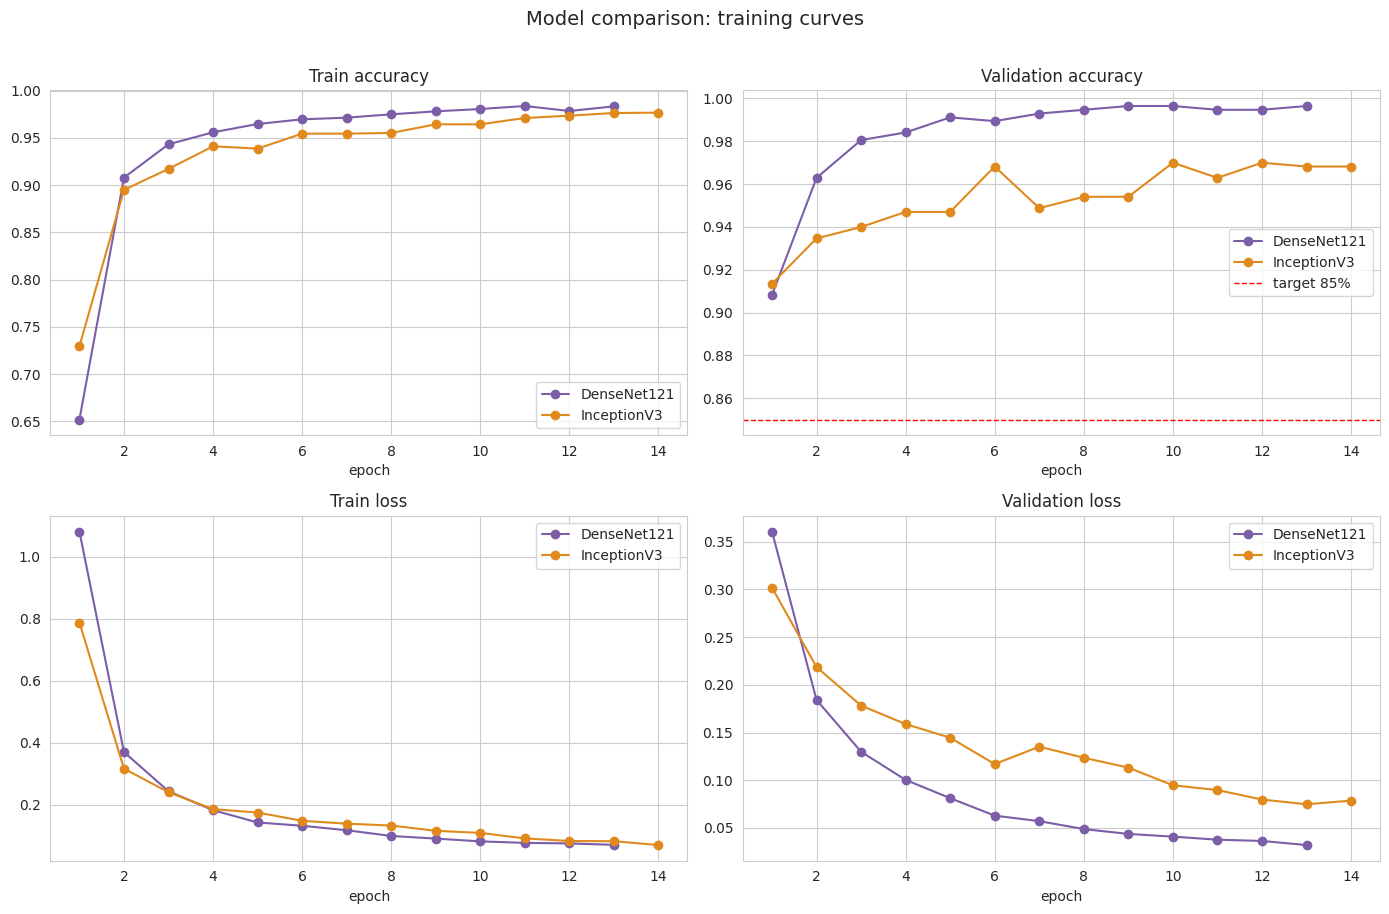

In [30]:
# ---- comparison: LINE graphs (training curves overlaid) ----
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
panels = (("accuracy", "Train accuracy", ax[0, 0]), ("val_accuracy", "Validation accuracy", ax[0, 1]),
          ("loss", "Train loss", ax[1, 0]), ("val_loss", "Validation loss", ax[1, 1]))
for key, title, a in panels:
    for name in MODEL_NAMES:
        h = histories[name]
        a.plot(np.arange(1, len(h[key]) + 1), h[key], marker="o", color=MODEL_COLORS[name], label=name)
    a.xaxis.set_major_locator(MaxNLocator(integer=True)); a.set_title(title); a.set_xlabel("epoch"); a.legend()
ax[0, 1].axhline(TARGET_ACC, color="red", ls="--", lw=1, label=f"target {TARGET_ACC:.0%}"); ax[0, 1].legend()
fig.suptitle("Model comparison: training curves", fontsize=14, y=1.01)
savefig("05_comparison_lines"); plt.show()

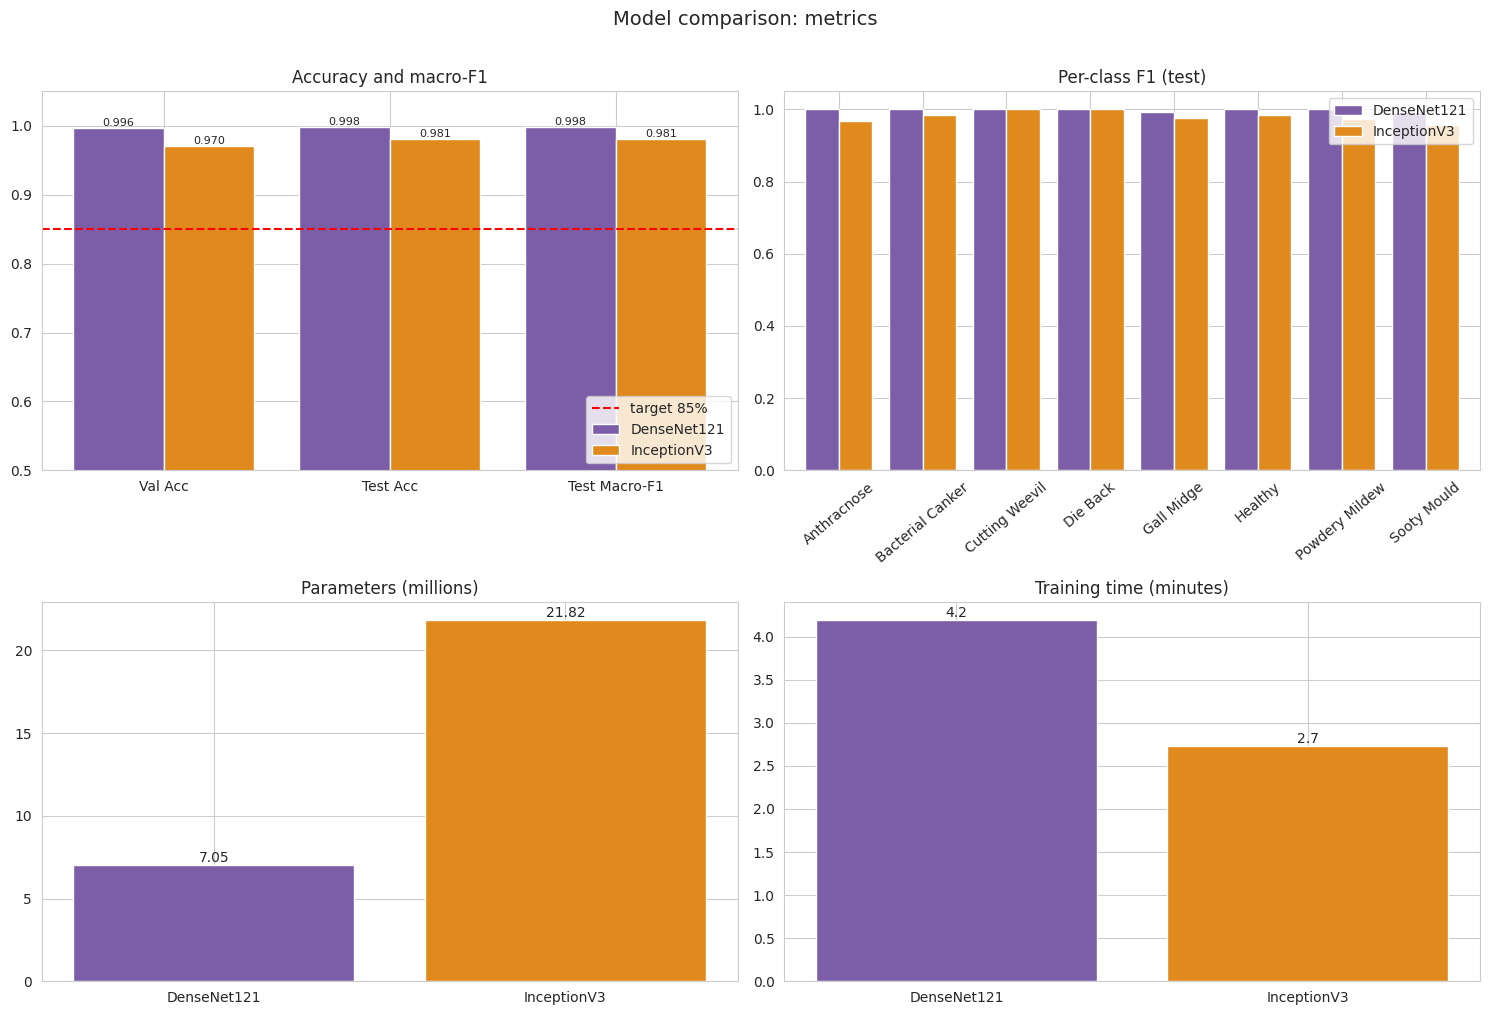

In [31]:
# ---- comparison: BAR graphs ----
fig, ax = plt.subplots(2, 2, figsize=(15, 10))
models = list(res["Model"])
n = len(models)

# (1) accuracy / F1 metrics, grouped by model
metrics = ["Val Acc", "Test Acc", "Test Macro-F1"]
x = np.arange(len(metrics)); w = 0.8 / n
for i, m in enumerate(models):
    vals = [res.loc[res.Model == m, k].values[0] for k in metrics]
    b = ax[0, 0].bar(x + (i - (n - 1) / 2) * w, vals, w, label=m, color=MODEL_COLORS[m])
    ax[0, 0].bar_label(b, fmt="%.3f", fontsize=8)
ax[0, 0].axhline(TARGET_ACC, color="red", ls="--", label=f"target {TARGET_ACC:.0%}")
ax[0, 0].set_xticks(x); ax[0, 0].set_xticklabels(metrics)
ax[0, 0].set_ylim(min(0.5, res[metrics].min().min() - 0.05), 1.05)
ax[0, 0].set_title("Accuracy and macro-F1"); ax[0, 0].legend(loc="lower right")

# (2) per-class F1, grouped by model
f1 = pd.DataFrame({m: [reports[m][c]["f1-score"] for c in class_names] for m in models}, index=class_names)
f1.plot(kind="bar", ax=ax[0, 1], width=0.8, color=[MODEL_COLORS[m] for m in models])
ax[0, 1].set_ylim(0, 1.05); ax[0, 1].set_title("Per-class F1 (test)"); ax[0, 1].tick_params(axis="x", rotation=40)

# (3) parameters
b = ax[1, 0].bar(models, res["Params (M)"], color=[MODEL_COLORS[m] for m in models])
ax[1, 0].bar_label(b, fmt="%.2f"); ax[1, 0].set_title("Parameters (millions)")

# (4) training time
b = ax[1, 1].bar(models, res["Train time (min)"], color=[MODEL_COLORS[m] for m in models])
ax[1, 1].bar_label(b, fmt="%.1f"); ax[1, 1].set_title("Training time (minutes)")

fig.suptitle("Model comparison: metrics", fontsize=14, y=1.01)
savefig("06_comparison_bars"); plt.show()

## Step 11. Best model and final result
The best model is chosen by **validation** accuracy (so the test set is never used for selection) and must reach **> 85% test accuracy**.

In [32]:
best_name = res.loc[1, "Model"]
best_row = res.loc[1]
best_model = trained[best_name]
best_pred = preds[best_name]

print("=" * 60)
print(f"BEST MODEL      : {best_name}")
print(f"Validation acc  : {best_row['Val Acc']:.4f}")
print(f"Test accuracy   : {best_row['Test Acc']:.4f}")
print(f"Test macro-F1   : {best_row['Test Macro-F1']:.4f}")
print("=" * 60)

passing = res[res["Test Acc"] > TARGET_ACC]
print(f"Models with test accuracy > {TARGET_ACC:.0%}: {', '.join(passing['Model']) if len(passing) else 'none'}")
if best_row["Test Acc"] > TARGET_ACC:
    print(f"RESULT: PASS. {best_name} exceeds the {TARGET_ACC:.0%} accuracy target.")
else:
    print(f"RESULT: FAIL. {best_name} is below the {TARGET_ACC:.0%} target; "
          "increase EPOCHS_*, unfreeze more layers, or try a larger input size.")

print("\nPer-class report for the best model:")
print(classification_report(y_true, best_pred, target_names=class_names, digits=3))

BEST MODEL      : DenseNet121
Validation acc  : 0.9965
Test accuracy   : 0.9983
Test macro-F1   : 0.9983
Models with test accuracy > 85%: DenseNet121, InceptionV3
RESULT: PASS. DenseNet121 exceeds the 85% accuracy target.

Per-class report for the best model:
                  precision    recall  f1-score   support

     Anthracnose      1.000     1.000     1.000        83
Bacterial Canker      1.000     1.000     1.000        71
  Cutting Weevil      1.000     1.000     1.000        96
        Die Back      1.000     1.000     1.000        52
      Gall Midge      0.987     1.000     0.994        78
         Healthy      1.000     1.000     1.000        66
  Powdery Mildew      1.000     1.000     1.000        57
     Sooty Mould      1.000     0.986     0.993        71

        accuracy                          0.998       574
       macro avg      0.998     0.998     0.998       574
    weighted avg      0.998     0.998     0.998       574



Saved best model.


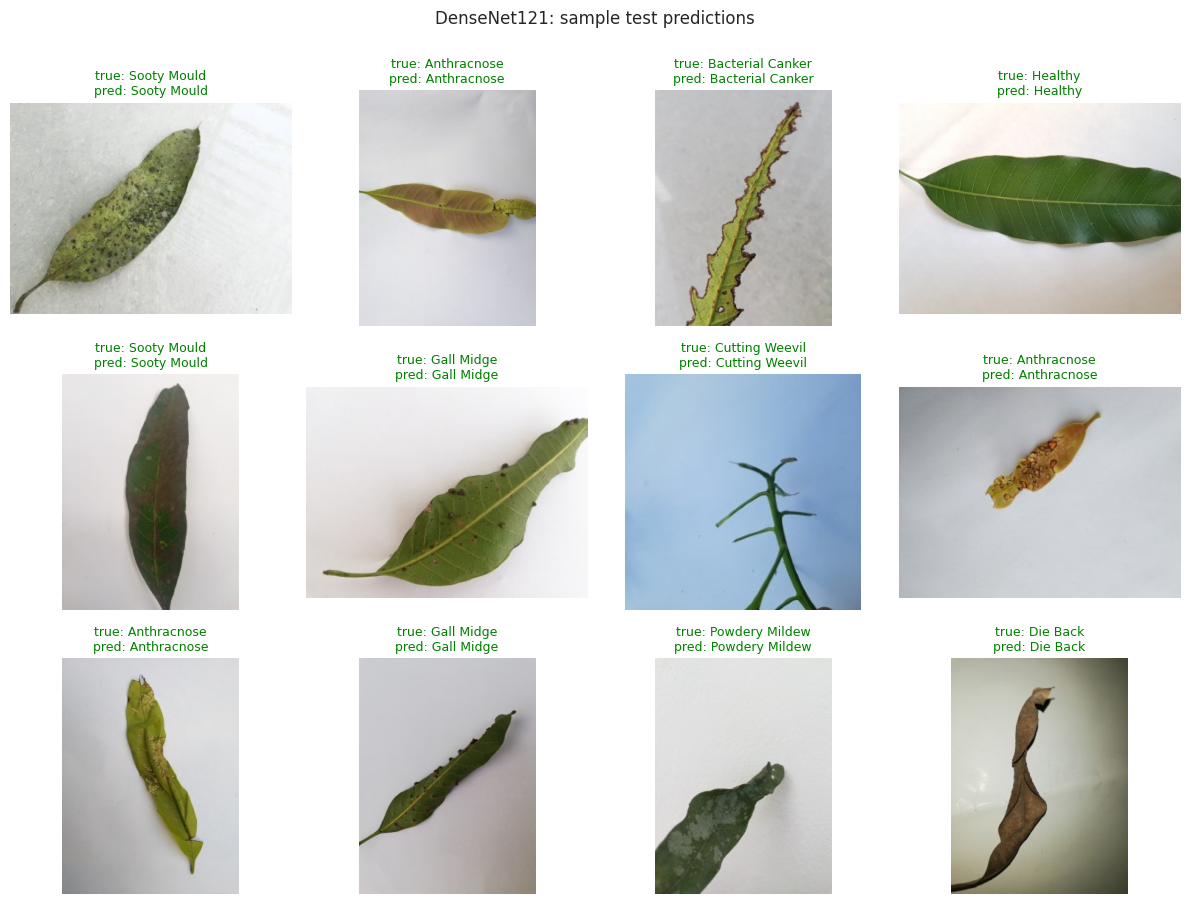

In [33]:
# save artifacts
res.to_csv(os.path.join(OUT_DIR, "model_comparison.csv"), index_label="rank")
try:
    best_model.save(os.path.join(OUT_DIR, f"best_model_{best_name}.keras"))
    print("Saved best model.")
except Exception as e:
    best_model.save_weights(os.path.join(OUT_DIR, f"best_model_{best_name}.weights.h5"))
    print("Full-model save failed (", type(e).__name__, "); saved weights instead.")

# sample predictions from the best model
idx = np.random.RandomState(SEED).choice(len(test_df), 12, replace=False)
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, i in zip(axes.flat, idx):
    row = test_df.iloc[i]
    ax.imshow(Image.open(row.path).convert("RGB")); ax.axis("off")
    ok = best_pred[i] == row.y
    ax.set_title(f"true: {class_names[row.y]}\npred: {class_names[best_pred[i]]}", fontsize=9,
                 color="green" if ok else "red")
plt.suptitle(f"{best_name}: sample test predictions", y=1.0)
plt.tight_layout(); plt.show()

## Final summary
- **Dataset:** MangoLeafBD (2022), 4,000 images, 8 balanced classes.
- **Checks done:** class balance, exact + near-duplicate detection, corrupt files, image size distribution.
- **Leakage control:** near-duplicates grouped so they never straddle train/val/test.
- **Models:** DenseNet121 and InceptionV3 (ImageNet transfer learning).
- **Best model and its accuracy:** printed in Step 11 (pass/fail against the 85% target).
- **Graphs (line + bar):** before preprocessing, after preprocessing, per-model evaluation, and model comparison. All figures are also saved as PNGs in `figures/` inside the output folder.
